In [1]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split

import torchvision
from torchvision.datasets import ImageFolder
from torchvision import transforms

import torchmetrics

import numpy as np
from matplotlib import pyplot as plt

from tqdm import tqdm
import random

In [2]:
def set_seed(seed):
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.use_deterministic_algorithms(True)

if torch.cuda.is_available():
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

# os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"  # wymagane przez niektóre operacje CUDA
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.mps.is_available() else "cpu")
device

device(type='mps')

## Data Load + Transform 

In [3]:
BATCH_SIZE = 128


transform = transforms.Compose([
    transforms.ToTensor(),
    # transforms.Normalize(0.5, 0.5, 0.5)
])

try:
    dataset = ImageFolder(root="data/", transform=transform)
    print(f"Loaded train dataset: {len(dataset)} images, {len(dataset.classes)} classes.")
except FileNotFoundError:
    print("Couldnt find 'data/' directory!!!!")

classes = dataset.classes
classes_num = len(classes)

Loaded train dataset: 39209 images, 43 classes.


In [4]:
train_dataset, test_dataset = random_split(dataset=dataset, lengths=[0.9, 0.1])
train_dataset, val_dataset = random_split(dataset=train_dataset, lengths=[8/9, 1/9])

In [5]:
for x, y in train_dataset:
    print(f"Input img shape: {x.shape}")
    print(f"class: {y}")
    break

Input img shape: torch.Size([3, 32, 32])
class: 2


In [6]:
data_loaders = {
    "train": DataLoader(dataset=train_dataset, shuffle=True, batch_size=BATCH_SIZE, pin_memory=True, num_workers=4),
    "val": DataLoader(dataset=val_dataset, shuffle=False, batch_size=BATCH_SIZE, num_workers=4),
    "test": DataLoader(dataset=test_dataset, shuffle=False, batch_size=BATCH_SIZE, num_workers=4)
}

## Architecture

### AutoEncoder (not used)

In [7]:
class EncoderAE(nn.Module):
    def __init__(self, input_size, input_channels, hidden_channels, latent_dim):
        super().__init__()
        
        self.input_size = input_size
        self.input_channels = input_channels
        self.hidden_channels = hidden_channels
        self.latent_dim = latent_dim
        
        self.encode = nn.Sequential([
            nn.Conv2d(in_channels=input_channels, out_channels=hidden_channels, kernel_size=(3,3), stride=2, padding=1), # 32x32 -> 16x16
            nn.LeakyReLU(),
            nn.Conv2d(in_channels=hidden_channels, out_channels=hidden_channels, kernel_size=(2,2), padding=1), # 16x16 -> 9x9
            nn.LeakyReLU(),
            nn.Conv2d(in_channels=hidden_channels, out_channels=2*hidden_channels, kernel_size=(2,2), padding=1), # 9x9 -> 10x10
            nn.LeakyReLU(),
            nn.Conv2d(in_channels=2*hidden_channels, out_channels=2*hidden_channels, kernel_size=(2,2), stride=2), # 10x10 -> 5x5
            nn.LeakyReLU(),
            nn.Flatten(),
            nn.Linear(in_features=2*hidden_channels*5*5, out_features=latent_dim)
        ])

    def forward(self, x):
        return self.encode(x)


In [8]:
class DecoderAE(nn.Module):
    def __init__(self, input_size, input_channels, hidden_channels, latent_dim):
        super().__init__()
        
        self.input_size = input_size
        self.input_channels = input_channels
        self.hidden_channels = hidden_channels
        self.latent_dim = latent_dim
        
        self.encode = nn.Sequential([
            nn.Conv2d(in_channels=input_channels, out_channels=hidden_channels, kernel_size=(3,3), stride=2, padding=1), # 32x32 -> 16x16
            nn.LeakyReLU(),
            nn.Conv2d(in_channels=hidden_channels, out_channels=hidden_channels, kernel_size=(2,2), padding=1), # 16x16 -> 9x9
            nn.LeakyReLU(),
            nn.Conv2d(in_channels=hidden_channels, out_channels=2*hidden_channels, kernel_size=(2,2), padding=1), # 9x9 -> 10x10
            nn.LeakyReLU(),
            nn.Conv2d(in_channels=2*hidden_channels, out_channels=2*hidden_channels, kernel_size=(2,2), stride=2), # 10x10 -> 5x5
            nn.LeakyReLU(),
            nn.Flatten(),
            nn.Linear(in_features=2*hidden_channels*5*5, out_features=latent_dim)
        ])


### VariationalAutoEncoder

In [9]:
class Encoder(nn.Module):
    def __init__(self, input_size, input_channels, hidden_dim, latent_dim):
        super().__init__()
        
        self.input_dim = input_size * input_size * input_channels
        self.hidden_dim = hidden_dim
        self.latent_dim = latent_dim
        
        self.fc1 = nn.Linear(in_features=self.input_dim, out_features=self.hidden_dim*2)
        self.fc2 = nn.Linear(in_features=self.hidden_dim*2, out_features=self.hidden_dim)
        self.fc3 = nn.Linear(in_features=self.hidden_dim, out_features=self.hidden_dim)
        self.fc_mean = nn.Linear(in_features=self.hidden_dim, out_features=self.latent_dim)
        self.fc_logvar = nn.Linear(in_features=self.hidden_dim, out_features=self.latent_dim)

        self.act = nn.LeakyReLU(0.1)

    def forward(self, x):
        x = torch.flatten(x, 1)
        x = self.act(self.fc1(x))
        x = self.act(self.fc2(x))
        x = self.act(self.fc3(x))
        mean = self.fc_mean(x)
        log_var = self.fc_logvar(x)
        
        return mean, log_var


In [10]:
class Decoder(nn.Module):
    def __init__(self, latent_dim, hidden_dim, output_size, output_channels):
        super().__init__()
        
        self.latent_dim = latent_dim
        self.hidden_dim = hidden_dim
        self.output_size = output_size
        self.output_channels = output_channels
        self.output_dim = output_size * output_size * output_channels
        
        self.fc1 = nn.Linear(in_features=self.latent_dim, out_features=self.hidden_dim)
        self.fc2 = nn.Linear(in_features=self.hidden_dim, out_features=self.hidden_dim)
        self.fc3 = nn.Linear(in_features=self.hidden_dim, out_features=self.hidden_dim*2)
        self.fc4 = nn.Linear(in_features=self.hidden_dim*2, out_features=self.output_dim)

        self.act = nn.LeakyReLU(0.1)

    def forward(self, x):
        x = self.act(self.fc1(x))
        x = self.act(self.fc2(x))
        x = self.act(self.fc3(x))
        x_hat = torch.sigmoid(self.fc4(x))
        x_hat = x_hat.view([-1, self.output_channels, self.output_size, self.output_size])
        return x_hat

In [11]:
class VAE(nn.Module):
    def __init__(self, input_size, input_channels, hidden_dim, latent_dim):
        super().__init__()
        self.encoder = Encoder(input_size=input_size, input_channels=input_channels, hidden_dim=hidden_dim, latent_dim=latent_dim)
        self.decoder = Decoder(latent_dim=latent_dim, hidden_dim=hidden_dim, output_size=input_size, output_channels=input_channels)

    def reparametrize(self, mean, logvar):
        std = torch.exp(0.5 * logvar)   # exp( log var ) --> var, sqrt(var) --> std
        eps = torch.rand_like(std)  # samples uniform distro
        return mean + std * eps # scales sampled uniform distro (eps) by std + adds mean of processed img - that way we get normal distro of img data 
    
    def forward(self, x):
        mean, logvar = self.encoder(x)
        z = self.reparametrize(mean=mean, logvar=logvar)
        x_hat = self.decoder(z)
        return x_hat, mean, logvar

Normal distribution: 

For z∼N(μ,σ2), we can use:

z = μ+σϵ, ϵ∼N(0,1)

In [12]:
""" My intuition behind reparametrization """

# given the assumption that latent space params are all from a given disribution, meaning last linear projection of encoder produces EX/mean and variance 
# - we cannot properly train decoder only on those values -> at beginning, params/weights of linear layer would be totally random, wouldn't fit in e.g. normal distribution 
# so passing them to decoder and training would reasult in having classic Autoencoder, without ability to sample latent vector
# we also cannot pass to decoder random sample from e.g. normal distribution, that way it wouldn't be connected with input data that should be reconstructed,
# that's why we sample normal disribution and scale it by 'mean' and 'variance' produced from last linear projection so we produce decoder input as scaled/shifted normal distro
# (scaled/shifted to input distro) - decoder learns to reconstruct orginal data from that distro, so after all to minimize reconstruction error, 
# params are adjusted and in next iters last linear projection producing mean and var gets better and better, finally producing proper gaussian distribution

"""
Reparametrization:

What about the sampling of the latent vector? 
Here’s there is a fundamental problem to the implementation. We are going to use back-propagation to tune the parameters ϕ and θ 
but sampling from latent space is an stochastic process that depends on ϕ! 
Instead of using complicating methods, we will tackle this problem with the reparametrization trick. 
The key idea is that we can move all the randomness to a distribution that does not change with the parameters, drawing instead a random variable

Then, to reproduce the sampling from

we have to shift the sample from ε and scale its variance

which holds because

You may have noticed that the layer that produces the variance is log_var . This is because we can write

There are various reasons to use the log variance instead of directly the variance, for example:
The variance is always positive, so we would have to force the layer in the encoder to only output positive values. Instead, the logarithm can be negative. 
Furthermore, taking the exponential in the last equation always leads to a positive number
We avoid problems with the square root of a negative number.
"""

'\nReparametrization:\n\nWhat about the sampling of the latent vector? \nHere’s there is a fundamental problem to the implementation. We are going to use back-propagation to tune the parameters ϕ and θ \nbut sampling from latent space is an stochastic process that depends on ϕ! \nInstead of using complicating methods, we will tackle this problem with the reparametrization trick. \nThe key idea is that we can move all the randomness to a distribution that does not change with the parameters, drawing instead a random variable\n\nThen, to reproduce the sampling from\n\nwe have to shift the sample from ε and scale its variance\n\nwhich holds because\n\nYou may have noticed that the layer that produces the variance is log_var . This is because we can write\n\nThere are various reasons to use the log variance instead of directly the variance, for example:\nThe variance is always positive, so we would have to force the layer in the encoder to only output positive values. Instead, the logarith

### VAE Training

In [13]:
class EarlyStopping:
    def __init__(self, patience=5, delta=0):
        self.patience = patience
        self.delta = delta
        self.best_score = None
        self.early_stop = False
        self.counter = 0
        self.best_model_state = None

    def __call__(self, val_loss, model):
        score = -val_loss

        if self.best_score is None:
            self.best_score = score
            self.best_model_state = model.state_dict()
        elif score < self.best_score + self.delta:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_score = score
            self.best_model_state = model.state_dict()
            self.counter = 0

    def load_best_model(self, model):
        model.load_state_dict(self.best_model_state)

In [14]:
def train(model: nn.Module, loaders: dict[DataLoader], criterion: nn.Module,
          optimizer: torch.optim.Optimizer, lr_scheduler: torch.optim.lr_scheduler, num_epochs: int, early_stopping: EarlyStopping):

    metric_loss = torchmetrics.aggregation.MeanMetric().to(device)
    val_losses = []

    for epoch in range(1, num_epochs+1):

        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()
            else:
                model.eval()

            for x, _ in tqdm(loaders[phase]):

                x = x.to(device)
                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == 'train'):  # there's no BatchNorm nor Dropout in NN but just for standarization net.train()/net.eval() is 
                    x_hat, mean, logvar = model(x)
                    loss = criterion(x, x_hat, mean, logvar)
                    
                    # if phase == 'train':
                    #     loss = criterion(x, x_hat, mean, logvar)
                    # else:
                    #     loss = torch.mean(torch.abs(x_hat - x).item())
                    
                    metric_loss(loss)

                    if phase == 'train':
                        loss.backward()
                        optimizer.step()
                    
            current_lr = lr_scheduler.get_last_lr()[0]
            mean_loss = metric_loss.compute()

            print(f"(Epoch {epoch}/[{phase}]) -> Loss:\t{mean_loss:.3f} -> lr: {current_lr}")
        
            if phase == "val":
                early_stopping(mean_loss, model)
                val_losses.append(float(mean_loss.cpu()))

            metric_loss.reset()

        if early_stopping.early_stop:
            print("Early stopping")
            break

        lr_scheduler.step()

    return early_stopping, val_losses

In [15]:
def vae_loss_function(x, x_hat, mean, log_var):
    reproduction_loss = nn.functional.mse_loss(x_hat, x, reduction='sum')
    KLD = -0.5 * torch.sum(1 + log_var - mean.pow(2) - log_var.exp())
    return reproduction_loss + KLD

In [16]:
for x, _ in train_dataset:
    input_channels, input_size = x.shape[0], x.shape[1]
    break

In [17]:
latent_dim = 64

vae = VAE(input_size=input_size, input_channels=input_channels, hidden_dim=256, latent_dim=latent_dim).to(device=device)
optim = torch.optim.Adam(vae.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer=optim, gamma=0.99)
early_stopping = EarlyStopping(patience=10, delta = 0.01)

  0%|          | 0/246 [00:00<?, ?it/s]/Users/kwasus/Desktop/STUDIA/SEM6/SSNE/Neural-Network-Concepts/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)
100%|██████████| 246/246 [00:26<00:00,  9.14it/s] 


(Epoch 1/[train]) -> Loss:	14568.198 -> lr: 0.001


100%|██████████| 31/31 [00:24<00:00,  1.27it/s]


(Epoch 1/[val]) -> Loss:	11206.267 -> lr: 0.001


100%|██████████| 246/246 [00:26<00:00,  9.34it/s] 


...

(Epoch 79/[val]) -> Loss:	4269.903 -> lr: 0.0004566097477439145


100%|██████████| 246/246 [00:26<00:00,  9.38it/s] 


(Epoch 80/[train]) -> Loss:	3876.350 -> lr: 0.00045204365026647533


100%|██████████| 31/31 [00:24<00:00,  1.28it/s]


(Epoch 80/[val]) -> Loss:	4265.983 -> lr: 0.00045204365026647533


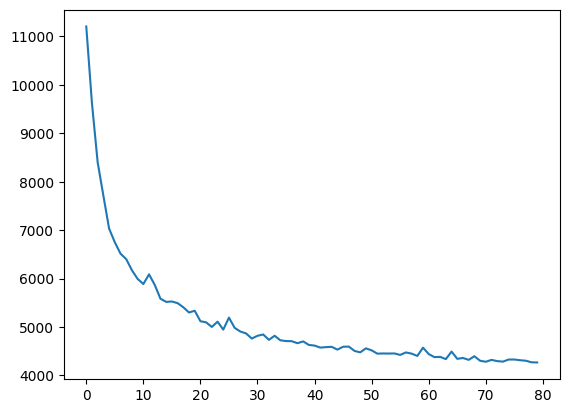

In [18]:
epochs = 80

early_stopping, lossses = train(model=vae, loaders=data_loaders, criterion=vae_loss_function, optimizer=optim, lr_scheduler=scheduler, num_epochs=epochs, early_stopping=early_stopping)
early_stopping.load_best_model(vae)

plt.plot(lossses)

In [19]:
torch.save(vae.state_dict(), f="vae_v1.pth")

### VAE results

In [20]:
def visualize_reconstructions(model, input_imgs, device):
    # Reconstruct images
    model.eval()
    with torch.no_grad():
        reconst_imgs, means, log_var = model(input_imgs.to(device))
    reconst_imgs = reconst_imgs.cpu()
    
    # Plotting
    imgs = torch.stack([input_imgs, reconst_imgs], dim=1).flatten(0,1)
    grid = torchvision.utils.make_grid(imgs, nrow=6, normalize=False)
    grid = grid.permute(1, 2, 0)
    if len(input_imgs) == 6:
        plt.figure(figsize=(15,10))
    else:
        plt.figure(figsize=(15,15))
    plt.title("Reconstructions")
    plt.imshow(grid)
    plt.axis('off')
    plt.show()

In [21]:
def generate_images(model, n_imgs, device):
    # Generate images
    model.eval()
    with torch.no_grad():
        generated_imgs = model.decoder(torch.randn([n_imgs, model.latent_dim]).to(device))
    generated_imgs = generated_imgs.cpu()
    
    grid = torchvision.utils.make_grid(generated_imgs, nrow=4, normalize=False) # produces 'channels first' format
    grid = grid.permute(1, 2, 0)    # matplotplit.imshow takes 'channels' last format
    if len(generated_imgs) == 6:
        plt.figure(figsize=(15,10))
    else:
        plt.figure(figsize=(15,15))
    plt.title("Generations")
    plt.imshow(grid)
    plt.axis('off')
    plt.show()

In [22]:
vae.eval()
with torch.inference_mode():    
    test_losses = []
    for x, _ in tqdm(data_loaders["test"]):
        x = x.to(device)
        x_hat, mean, logvar = vae(x)
        loss = vae_loss_function(x, x_hat, mean, logvar)
        test_losses.append(loss.item())
    print(f"Mean test loss: {np.mean(np.array(test_losses))}")

100%|██████████| 31/31 [00:24<00:00,  1.27it/s]

Mean test loss: 4209.983012537802


torch.Size([27, 3, 32, 32])


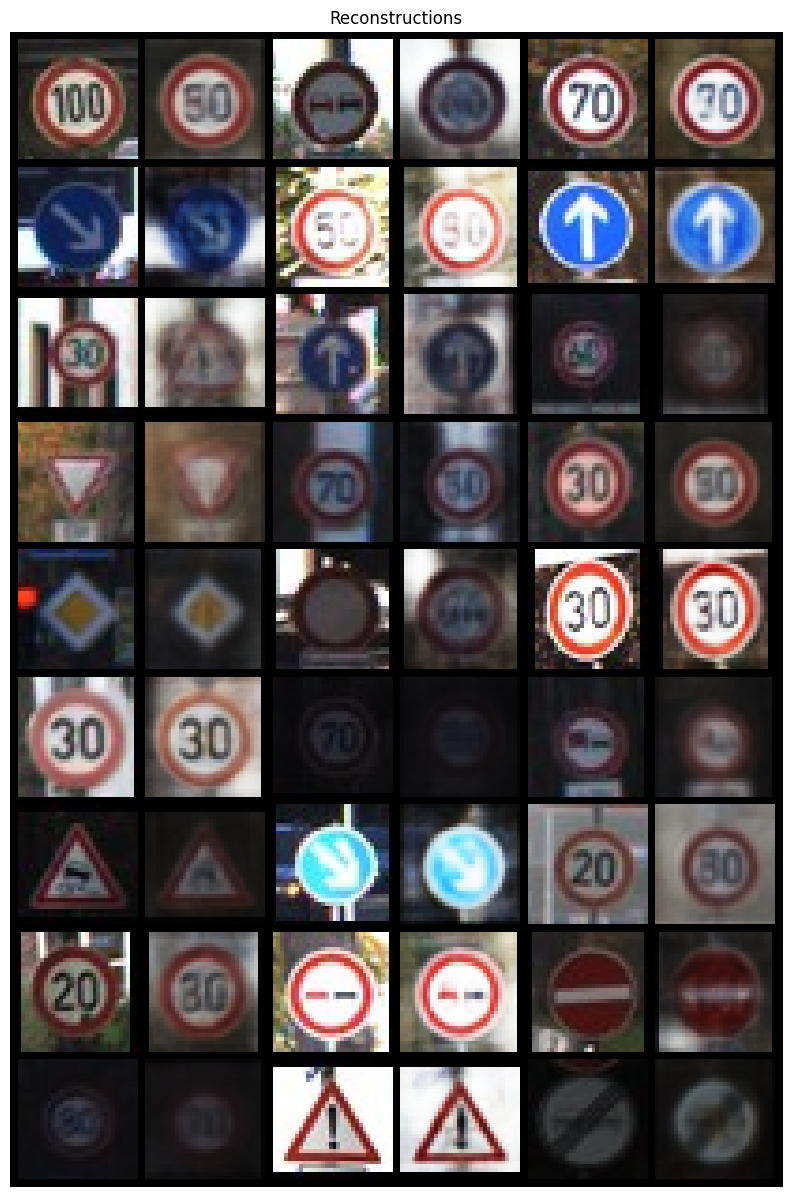

In [23]:
n_samples = 27
sample_imgs = torch.stack([data_loaders["test"].dataset[i][0] for i in range(n_samples)], dim=0)    # wraps all tensors in one one external tensor - [[..], [..], .., [..]]
print(sample_imgs.shape)
visualize_reconstructions(vae, input_imgs=sample_imgs, device=device)

### FID Evaluation

In [24]:
vae = VAE(input_size=input_size, input_channels=input_channels, hidden_dim=256, latent_dim=latent_dim).to(device=device)
vae.load_state_dict(torch.load(f="vae_v1.pth"))

<All keys matched successfully>

#### Evaluator

In [25]:
class Evaluator(nn.Module):
    def __init__(self, input_dim, hidden_dim, classes_num):
        super(Evaluator, self).__init__()

        self.fc_1 = nn.Linear(input_dim, hidden_dim)
        self.fc_2 = nn.Linear(hidden_dim, 100)
        self.fc_out  = nn.Linear(100, classes_num)
        
        self.LeakyReLU = nn.LeakyReLU(0.2)
        
    def get_features(self, x):
        x = torch.flatten(x, 1)
        x = self.LeakyReLU(self.fc_1(x))
        x = self.LeakyReLU(self.fc_2(x))
        return x
    

    def forward(self, x):
        x = self.get_features(x)
        x = self.fc_out(x)
        return x

evaluator = Evaluator(input_size * input_size * input_channels, 256, classes_num).to(device)

In [26]:
# Optimizers
optimizer = torch.optim.Adam(evaluator.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer=optimizer, gamma=0.97)

# loss
criterion = nn.CrossEntropyLoss()

In [27]:
num_epochs = 50
for epoch in tqdm(range(num_epochs)):
    for data, targets in data_loaders["train"]:
        data = data.to(device)
        targets = targets.to(device)

        results = evaluator(data)
        loss = criterion(results, targets)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

100%|██████████| 50/50 [21:35<00:00, 25.90s/it]


In [28]:
num_correct = 0
total_guesses = 0

evaluator.eval()
with torch.no_grad():
    for data, targets in data_loaders["test"]:
        # Sends data and targets to device
        data = data.to(device)
        targets = targets.to(device)

        # Acquires the network's best guesses at each class
        results = evaluator(data)
        best_guesses = torch.argmax(results, 1)

        # Updates number of correct and total guesses
        num_correct += torch.eq(targets, best_guesses).sum().item()
        total_guesses += len(targets)

print("Correctly guessed ", num_correct/total_guesses*100, "% of the dataset")

Correctly guessed  92.98469387755102 % of the dataset


In [29]:
test_data = [x for x, _ in data_loaders["test"]]
print(len(test_data), test_data[0].shape)
test_data = torch.cat(test_data)    # turns list of batches into one vector (without batch division)
test_data.shape

31 torch.Size([128, 3, 32, 32])


torch.Size([3920, 3, 32, 32])

In [30]:
latent_dim = 64

with torch.no_grad():
    fixed_noise = torch.randn(1000, latent_dim, device=device)
    generations_vae = vae.decoder(fixed_noise)
    dist_generations_vae = evaluator.get_features(generations_vae.to(device)).cpu()
    dist_test_data = evaluator.get_features(test_data.to(device)).cpu()

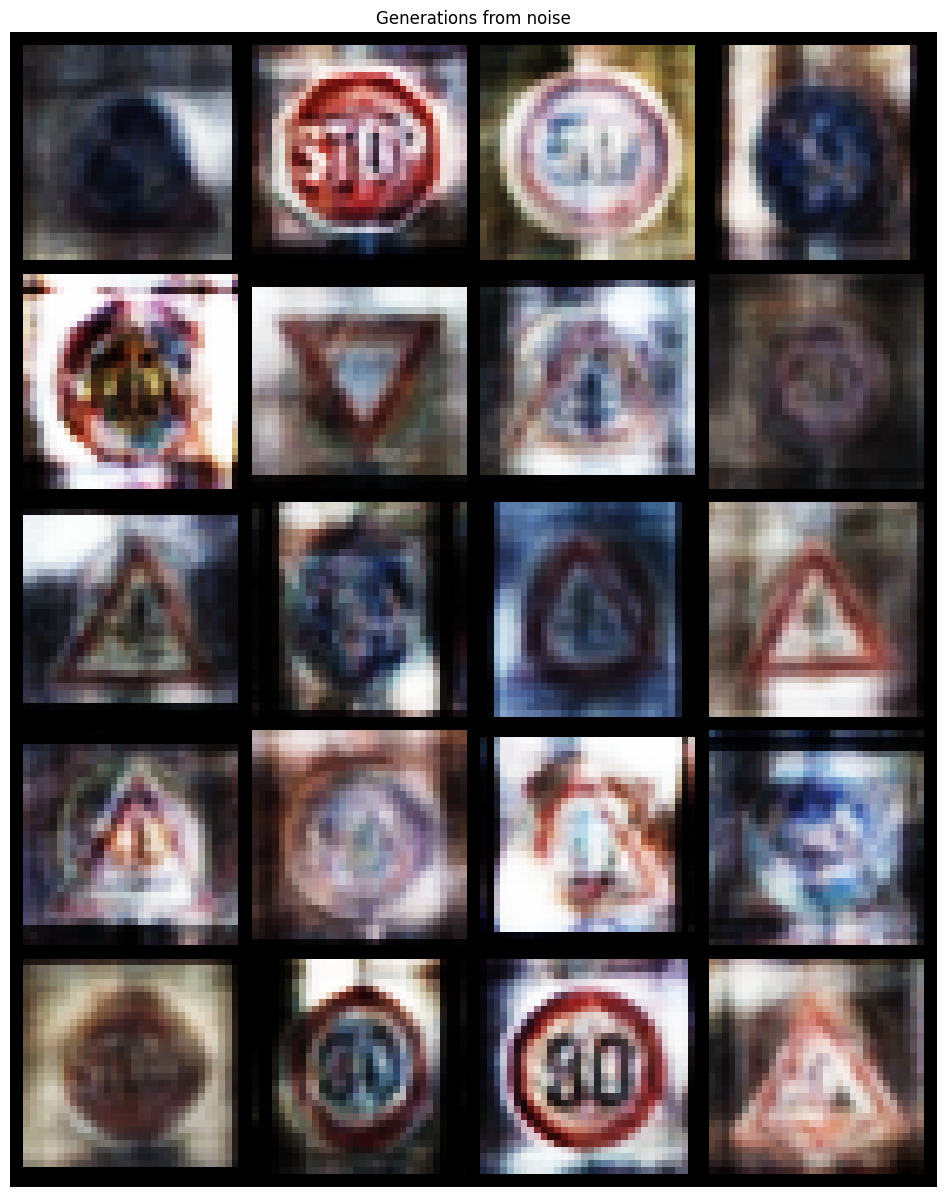

In [36]:
grid = torchvision.utils.make_grid(generations_vae.cpu()[:20], nrow=4, normalize=False) # produces 'channels first' format
grid = grid.permute(1, 2, 0)    # matplotplit.imshow takes 'channels' last format
if len(generations_vae) == 4:
    plt.figure(figsize=(15,10))
else:
    plt.figure(figsize=(15,15))
plt.title("Generations from noise")
plt.imshow(grid)
plt.axis('off')
plt.show()

In [34]:
print(generations_vae.shape)
torch.save(generations_vae.cpu().detach(),"poniedzialek_Bargieł_Kwaśniak.pt")

torch.Size([1000, 3, 32, 32])


#### FID impl

In [31]:
######### Frechet Inception distance based on implementation from https://github.com/mseitzer/pytorch-fid

import numpy as np
from scipy import linalg


def calculate_frechet_distance(distribution_1, distribution_2, eps=1e-6):
    mu1 = np.mean(distribution_1, axis=0)
    sigma1 = np.cov(distribution_1, rowvar=False)

    mu2 = np.mean(distribution_2, axis=0)
    sigma2 = np.cov(distribution_2, rowvar=False)

    """Numpy implementation of the Frechet Distance.
    The Frechet distance between two multivariate Gaussians X_1 ~ N(mu_1, C_1)
    and X_2 ~ N(mu_2, C_2) is
            d^2 = ||mu_1 - mu_2||^2 + Tr(C_1 + C_2 - 2*sqrt(C_1*C_2)).
    Stable version by Dougal J. Sutherland.
    Params:
    -- mu1   : Numpy array containing the activations of a layer of the
               inception net (like returned by the function 'get_predictions')
               for generated samples.
    -- mu2   : The sample mean over activations, precalculated on an
               representative data set.
    -- sigma1: The covariance matrix over activations for generated samples.
    -- sigma2: The covariance matrix over activations, precalculated on an
               representative data set.
    Returns:
    --   : The Frechet Distance.
    """

    mu1 = np.atleast_1d(mu1)
    mu2 = np.atleast_1d(mu2)

    sigma1 = np.atleast_2d(sigma1)
    sigma2 = np.atleast_2d(sigma2)

    assert mu1.shape == mu2.shape, \
        'Training and test mean vectors have different lengths'
    assert sigma1.shape == sigma2.shape, \
        'Training and test covariances have different dimensions'

    diff = mu1 - mu2

    # Product might be almost singular
    covmean, _ = linalg.sqrtm(sigma1.dot(sigma2), disp=False)
    if not np.isfinite(covmean).all():
        msg = ('fid calculation produces singular product; '
               'adding %s to diagonal of cov estimates') % eps
        print(msg)
        offset = np.eye(sigma1.shape[0]) * eps
        covmean = linalg.sqrtm((sigma1 + offset).dot(sigma2 + offset))

    # Numerical error might give slight imaginary component
    if np.iscomplexobj(covmean):
        if not np.allclose(np.diagonal(covmean).imag, 0, atol=1e-3):
            m = np.max(np.abs(covmean.imag))
            raise ValueError('Imaginary component {}'.format(m))
        covmean = covmean.real

    tr_covmean = np.trace(covmean)

    return (diff.dot(diff) + np.trace(sigma1) +
            np.trace(sigma2) - 2 * tr_covmean)

In [32]:
# for name, obj in zip(["vae_generations"], [dist_generations_vae.numpy()]):
#     print(f"FD {name}: {calculate_frechet_distance(dist_test_data.numpy(), obj)}")

print(f"FD vae_generations: {calculate_frechet_distance(dist_test_data.numpy(), dist_generations_vae.numpy())}")

FD vae_generations: 1049.2428240768422


/var/folders/w2/3khqjd7d1m97phfx15lm1wyr0000gn/T/ipykernel_3504/2261845342.py:46: DeprecationWarning: The `disp` argument is deprecated and will be removed in SciPy 1.18.0.
  covmean, _ = linalg.sqrtm(sigma1.dot(sigma2), disp=False)


- FID from torchmetrics (but not working)

In [33]:
# https://lightning.ai/docs/torchmetrics/stable/image/frechet_inception_distance.html
# from torchmetrics.image.fid import FrechetInceptionDistance


# latent_dim = 64

# fid = FrechetInceptionDistance(feature=2048)
# test_data = (test_data * 255).clamp(0, 255).to(torch.uint8)
# fid.update(imgs=test_data, real=True)
# with torch.inference_mode():
#     fixed_noise = torch.randn(1000, latent_dim, device=device)   # 1000 random samples from normal distribution - passed
#     generations_vae = vae.decoder(fixed_noise)
#     generations_vae = (generations_vae * 255).clamp(0, 255).to(torch.uint8)
#     fid.update(generations_vae, real=False)

# score = fid.compute()
# print(f"FID score: {score.item()}")